<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: E-Commerce Dynamic Price Prediction</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Loading & Dimensionality Assessment (5 Marks)

Load the 'diamonds' dataset via the OpenML repository to access a standard retail jewelry dataset. Extract it into a Pandas DataFrame and display the first five rows alongside the dataset's overall dimensions.

**Hint:** Utilize the dataset fetching functionality from `sklearn.datasets` referencing the correct string identifier (`name="diamonds"`). Ensure the returned object is formatted as a structured DataFrame.

**Expected Output:** A pandas DataFrame displaying the numerical and categorical features of the retail items, along with a tuple representing the total number of rows and columns.

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml

In [2]:
diamonds = fetch_openml(name='diamonds', as_frame = True)

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name diamonds exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=42225
- version 2, status: active
  url: https://www.openml.org/search?type=data&id=43998

  warn(warning_msg)


In [3]:
df = diamonds.frame

In [4]:
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [5]:
df.shape

(53940, 10)

### Question 2: Invalid Data Cleaning & Reasoning (6 Marks)

In physical retail products, spatial dimensions cannot be zero. Identify and remove any rows where the dimension features ('x', 'y', or 'z') have a value of exactly 0. Print the number of rows removed. Additionally, provide a brief analytical justification for why dropping these rows is preferable to imputing them with the feature mean in this specific context. Print your written answer using Python `print()` statements.

**Hint:** Construct a boolean mask to filter out anomalous rows. Calculate the difference in row counts before and after the operation.

**Expected Output:** A printed statement detailing the exact count of anomalous rows dropped, the new shape of the DataFrame, and a printed analytical paragraph justifying the chosen data cleaning strategy.

In [6]:
rows = df.shape[0]

In [7]:
mask = (df["x"] != 0) & (df["y"] != 0) & (df["z"] != 0)

In [8]:
df = df[mask].copy()

In [9]:
rows_removed = rows - df.shape[0]

In [10]:
print(f"Number of anomalous rows dropped: {rows_removed}")
print(f"New shape of the DataFrame: {df.shape}")

Number of anomalous rows dropped: 20
New shape of the DataFrame: (53920, 10)


In [11]:
###Justification
print("Justification")
print("Zero dimensions are physically invalid, so dropping these rows is preferable to mean imputation,\nwhich would introduce artificial values and hamper relationships between dimensions, carat and price.")

Justification
Zero dimensions are physically invalid, so dropping these rows is preferable to mean imputation,
which would introduce artificial values and hamper relationships between dimensions, carat and price.


### Question 3: Categorical Feature Encoding (6 Marks)

The dataset contains categorical features ('cut', 'color', 'clarity') that possess a strict ordinal hierarchy. Map these categorical text values into sequential integers representing their quality ranking from lowest to highest. To ensure standardization, use the following strict industry hierarchies (listed from lowest to highest quality):

*   **Cut:** Fair < Good < Very Good < Premium < Ideal
*   **Color:** J < I < H < G < F < E < D
*   **Clarity:** I1 < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF

**Hint:** Define explicit mapping dictionaries based on the provided hierarchies and apply them to the respective columns to overwrite the text values.

**Expected Output:** A transformed DataFrame where the specified text-based categorical columns have been replaced entirely by standardized integer scales.

In [12]:
cut_map = {
    'Fair': 1,
    'Good': 2,
    'Very Good': 3,
    'Premium': 4,
    'Ideal': 5
}

In [13]:
colour_map = {
    'J': 1,
    'I': 2,
    'H': 3,
    'G': 4,
    'F': 5,
    'E': 6,
    'D': 7
}

In [14]:
clarity_map = {
    'I1': 1,
    'SI2': 2,
    'SI1': 3,
    'VS2': 4,
    'VS1': 5,
    'VVS2': 6,
    'VVS1': 7,
    'IF': 8
}

In [15]:
df['cut'] = df['cut'].map(cut_map)
df['color'] = df['color'].map(colour_map)
df['clarity'] = df['clarity'].map(clarity_map)

df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31
2,0.23,2,6,5,56.9,65.0,327,4.05,4.07,2.31
3,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63
4,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75


### Question 4: Outlier Treatment via IQR (6 Marks)

Extreme pricing anomalies can skew regression models. Implement the Interquartile Range (IQR) method specifically on the target variable ('price') to detect outliers. Remove any rows that fall outside the standard $1.5 \times IQR$ boundary.

**Hint:** Calculate the first and third quartiles of the target variable to establish the IQR, then filter the DataFrame to retain only the observations within the calculated lower and upper bounds.

**Expected Output:** A quantitative summary showing the original row count, the number of outlier rows discarded, and the finalized row count of the cleaned dataset.

In [16]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

In [17]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

original_count = len(df)

df = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

In [18]:
outliers_removed = original_count - len(df)

final_count = len(df)

print("Original row count:", original_count)
print("Number of outlier rows discarded:", outliers_removed)
print("Finalized row count:", final_count)

Original row count: 53920
Number of outlier rows discarded: 3532
Finalized row count: 50388


### Question 5: Exploratory Data Analysis & Multicollinearity (7 Marks)

Compute and visualize a correlation matrix for the continuous numerical variables in the dataset. Identify which features exhibit strong multicollinearity with one another. Print your written answer using Python `print()` statements detailing your observations and explaining mathematically or structurally why multicollinearity can be problematic for distance-based or linear models.

**Hint:** Utilize standard data visualization libraries to generate a heatmap of the correlation coefficients. Focus your written analysis on predictor variables that share very high correlation scores.

**Expected Output:** A visual heatmap plot displaying correlation values, accompanied by a printed analytical text block discussing the observed multicollinearity and its implications.

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']

corr_matrix = df[numerical_cols].corr()

Correlation Matrix:
          carat     depth     table     price         x         y         z
carat  1.000000  0.046519  0.183614  0.915873  0.982623  0.974326  0.960762
depth  0.046519  1.000000 -0.291905  0.004169 -0.015886 -0.019218  0.114996
table  0.183614 -0.291905  1.000000  0.128111  0.194030  0.185230  0.145964
price  0.915873  0.004169  0.128111  1.000000  0.897485  0.892790  0.873153
x      0.982623 -0.015886  0.194030  0.897485  1.000000  0.991181  0.968581
y      0.974326 -0.019218  0.185230  0.892790  0.991181  1.000000  0.962888
z      0.960762  0.114996  0.145964  0.873153  0.968581  0.962888  1.000000


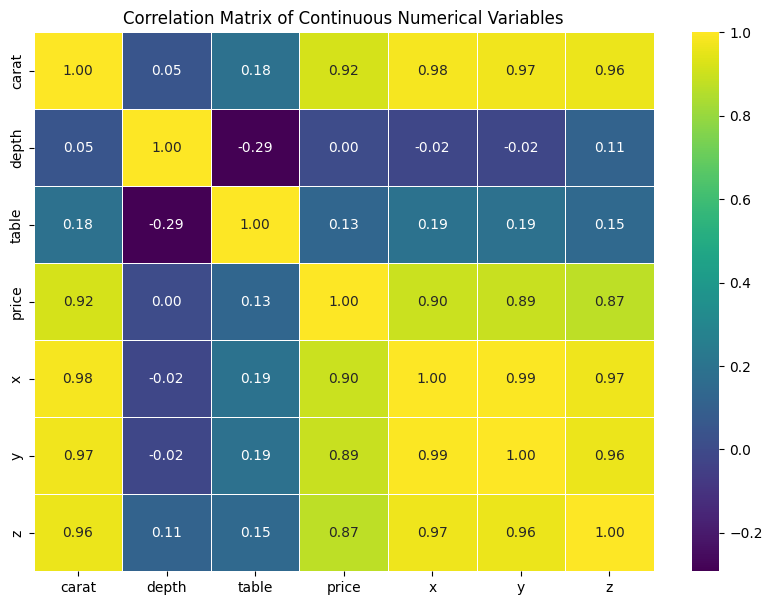

In [20]:
print("Correlation Matrix:")
print(corr_matrix)

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='viridis',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Continuous Numerical Variables')
plt.show()

In [21]:
print("\n--- Multicollinearity Analysis ---")


--- Multicollinearity Analysis ---


In [22]:
print("""
The correlation matrix shows a very strong positive correlation between
carat and price. This is expected because larger diamonds generally have
higher prices.

The variables x, y, and z also show strong correlations with carat because
they represent the physical dimensions of the diamond and generally
increase as carat size increases.

Therefore, carat, x, y, and z exhibit significant multicollinearity.
These variables contain overlapping information about the physical size
of a diamond.
""")


The correlation matrix shows a very strong positive correlation between
carat and price. This is expected because larger diamonds generally have
higher prices.

The variables x, y, and z also show strong correlations with carat because
they represent the physical dimensions of the diamond and generally
increase as carat size increases.

Therefore, carat, x, y, and z exhibit significant multicollinearity.
These variables contain overlapping information about the physical size
of a diamond.



In [23]:
print("""
Multicollinearity can be problematic for linear regression because highly
correlated predictors make it difficult to determine the individual effect
of each feature on the target variable. It can lead to unstable regression
coefficients, inflated standard errors, and unreliable interpretations.

Mathematically, if two predictors are highly correlated, their columns in
the feature matrix X become close to linearly dependent. Consequently,
X^T X becomes close to singular, making the calculation of regression
coefficients unstable.

For distance-based models, highly correlated features can cause the same
underlying information to be counted multiple times in the distance
calculation. For example, if carat, x, y, and z all represent diamond
size, their simultaneous inclusion can give excessive importance to size
when calculating distances between observations.
""")


Multicollinearity can be problematic for linear regression because highly
correlated predictors make it difficult to determine the individual effect
of each feature on the target variable. It can lead to unstable regression
coefficients, inflated standard errors, and unreliable interpretations.

Mathematically, if two predictors are highly correlated, their columns in
the feature matrix X become close to linearly dependent. Consequently,
X^T X becomes close to singular, making the calculation of regression
coefficients unstable.

For distance-based models, highly correlated features can cause the same
underlying information to be counted multiple times in the distance
calculation. For example, if carat, x, y, and z all represent diamond
size, their simultaneous inclusion can give excessive importance to size
when calculating distances between observations.



### Question 6: Data Splitting and Standardization (6 Marks)

Separate the dataset into feature columns (X) and the target variable (y = 'price'). Split these arrays into training and testing sets utilizing an 80/20 ratio. Apply standard scaling to the training features and transform the testing features accordingly. You must explicitly convert the resulting scaled numerical arrays back into Pandas DataFrames to retain the original column names for subsequent feature interpretation.

**Hint:** Ensure the scaler is fitted solely on the training data to prevent data leakage. Reconstruct the DataFrames using the scaled arrays and the column attributes from the original feature set.

**Expected Output:** Four pandas DataFrames or NumPy arrays representing the scaled predictors (as DataFrames with column headers) and their target values for both the training and testing phases.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [25]:
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)


In [26]:
print("X_train_scaled:")
print(X_train_scaled_df.head())

print("\nX_test_scaled:")
print(X_test_scaled_df.head())

print("\nTraining target (y_train):")
print(y_train.head())

print("\nTesting target (y_test):")
print(y_test.head())

print("\nShapes:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train_scaled:
          carat       cut     color   clarity     depth     table         x  \
12890  1.679918  0.081169 -2.037087  0.556931 -1.231495  2.060452  1.665172   
9117   0.744323  0.081169  0.326529 -1.262102 -0.035521  1.161743  0.780866   
12147  0.718334 -1.704318  1.508337 -0.049413  0.245884  2.959162  0.800964   
33941 -1.126868  0.973912 -0.855279  0.556931  0.456939 -1.534385 -1.359557   
27047 -1.048901  0.973912 -0.855279  1.163276  0.034830 -1.085031 -1.208823   

              y         z  
12890  1.630136  1.392894  
9117   0.837132  0.776423  
12147  0.766866  0.792230  
33941 -1.331080 -1.262674  
27047 -1.170471 -1.152025  

X_test_scaled:
          carat       cut     color   clarity     depth     table         x  \
7172   0.510424 -1.704318  0.917433 -0.655757  1.371507 -0.186321  0.559789   
7835   0.744323  0.973912 -0.264375 -1.262102 -0.176224 -0.186321  0.921551   
46177 -0.321216  0.973912 -0.264375 -0.049413  0.245884 -0.186321 -0.153685   
36953 -1.

### Question 7: Baseline Linear Regression (5 Marks)

Train a baseline Linear Regression model on the scaled training dataset. Once trained, generate an array of price predictions using the scaled test dataset.

**Hint:** Instantiate the standard linear modeling class, fit it using the training predictors and targets, and apply the prediction method to the test predictors.

**Expected Output:** A one-dimensional array containing continuous numerical values representing the model's estimated retail prices for the test set.

In [27]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

y_pred = lr_model.predict(X_test_scaled)

print("Predicted Prices:")
print(y_pred)

Predicted Prices:
[4312.54859752 4481.89192093 2144.16784052 ... 7058.83367058 2591.35012811
 1600.66398293]


### Question 8: Baseline Model Evaluation & Interpretation (6 Marks)

Quantify the performance of your baseline Linear Regression model by calculating three specific metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R-squared score ($R^2$). Print your written answer using Python `print()` statements to explain what the calculated RMSE value implies about the average prediction error in the specific context of retail jewelry pricing.

**Hint:** Utilize standard regression metric functions. Consider the units of the target variable when interpreting the RMSE value.

**Expected Output:** A formatted text block printing the calculated values for MAE, RMSE, and $R^2$, followed by a qualitative paragraph interpreting the real-world meaning of the RMSE magnitude.

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [30]:
print(f"--- Baseline metrics ---")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2   : {r2:.4f}")

--- Baseline metrics ---
MAE  : 599.44
RMSE : 874.36
R2   : 0.8987


In [31]:
print(
    f"The RMSE of {rmse:.2f} means that the model's prediction errors\n"
    f"are typically around {rmse:.2f} price units. Since the target variable\n"
    f"'price' represents the retail price of the diamond, this indicates\n"
    f"that the baseline Linear Regression model has a prediction error\n"
    f"magnitude of approximately {rmse:.2f} price units. RMSE gives greater\n"
    f"weight to large prediction errors, making it useful for identifying\n"
    f"whether the model occasionally makes substantially inaccurate price predictions.\n"
)

The RMSE of 874.36 means that the model's prediction errors
are typically around 874.36 price units. Since the target variable
'price' represents the retail price of the diamond, this indicates
that the baseline Linear Regression model has a prediction error
magnitude of approximately 874.36 price units. RMSE gives greater
weight to large prediction errors, making it useful for identifying
whether the model occasionally makes substantially inaccurate price predictions.



### Question 9: Custom Regression Metric - Asymmetric Pricing Error (8 Marks)

In retail pricing, underpricing a product immediately costs the company profit margins, whereas overpricing reduces conversion probability. Write a custom python function that calculates an Asymmetric Mean Absolute Error. This metric must apply a 2x penalty weight to underpriced predictions (prediction < actual) compared to overpriced predictions (prediction >= actual). Compute this score for your baseline model.

**Hint:** Calculate the raw error difference for each test instance. Implement conditional logic (or vectorized equivalent) to double the absolute error when the predicted value falls short of the true value, then return the overall mean.

**Expected Output:** A single float value representing the custom business penalty score for the baseline linear model.

In [32]:
def asymmetric_mae(y_actual, y_predicted):
    errors = np.abs(y_actual - y_predicted)

    weights = np.where(y_predicted < y_actual, 2, 1)

    return np.mean(errors * weights)

asymmetric_error = asymmetric_mae(y_test, y_pred)
print("Asymmetric Mean Absolute Error:", asymmetric_error)

Asymmetric Mean Absolute Error: 903.6296276937672


### Question 10: Ridge Regression & Hyperparameter Tuning (8 Marks)

To address the potential multicollinearity identified during your EDA, implement Ridge Regression. Utilize a Grid Search with cross-validation to find the optimal regularization parameter (alpha) from a predefined sequence of values (e.g., 0.1, 1.0, 10.0, 100.0). Train the optimal model and calculate the $R^2$ score on the test set. Print your written answer using Python `print()` statements to explain the mechanism by which Ridge regularization mitigates the effects of correlated features.

**Hint:** Construct a parameter grid dictionary and apply cross-validated grid search methodology. Analyze how the L2 penalty alters the magnitude of model coefficients.

**Expected Output:** The optimal alpha parameter found during tuning, the resulting $R^2$ score on the test data, and a printed analytical explanation of the regularization process.

In [37]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

In [42]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

In [43]:
ridge_grid.fit(X_train, y_train)

best_ridge = ridge_grid.best_estimator_

y_pred_ridge = best_ridge.predict(X_test)
ridge_test_r2 = r2_score(y_test, y_pred_ridge)

print("Optimal alpha:", ridge_grid.best_params_["ridge__alpha"])
print("Best Cross-Validation R²:", round(ridge_grid.best_score_, 4))
print("Test Set R² Score:", round(ridge_test_r2, 4))

print("\nExplanation of Ridge Regularization:")
print(
    "Ridge Regression addresses multicollinearity by adding an L2 "
    "regularization penalty to the ordinary least squares objective. "
    "It penalizes the sum of squared regression coefficients, shrinking "
    "their magnitudes toward zero without generally making them exactly zero."
)
print(
    "When features are highly correlated, ordinary linear regression "
    "can produce unstable coefficients because multiple features explain "
    "similar variations in the target. Ridge regularization discourages "
    "excessively large coefficients and distributes their influence more "
    "stably, reducing variance and potentially improving generalization."
)
print(
    "The alpha parameter controls regularization strength. A larger alpha "
    "means stronger shrinkage, while a smaller alpha means weaker "
    "regularization. Grid Search with cross-validation selects the alpha "
    "with the best average validation R² among the tested values."
)


Optimal alpha: 100.0
Best Cross-Validation R²: 0.9007
Test Set R² Score: 0.8986

Explanation of Ridge Regularization:
Ridge Regression addresses multicollinearity by adding an L2 regularization penalty to the ordinary least squares objective. It penalizes the sum of squared regression coefficients, shrinking their magnitudes toward zero without generally making them exactly zero.
When features are highly correlated, ordinary linear regression can produce unstable coefficients because multiple features explain similar variations in the target. Ridge regularization discourages excessively large coefficients and distributes their influence more stably, reducing variance and potentially improving generalization.
The alpha parameter controls regularization strength. A larger alpha means stronger shrinkage, while a smaller alpha means weaker regularization. Grid Search with cross-validation selects the alpha with the best average validation R² among the tested values.


In [44]:
print("""
Ridge Regression uses L2 regularization, which adds a penalty based on
the squared magnitude of the model coefficients. When predictor variables
are highly correlated, such as carat, x, y and z, ordinary Linear Regression can produce unstable or
excessively large coefficients because these features contain overlapping information.

Ridge regularization reduces the magnitude of these coefficients by
applying an L2 penalty. Instead of allowing correlated features to have
large and unstable coefficients, Ridge distributes their influence more
smoothly across the correlated predictors.

A larger alpha produces stronger coefficient shrinkage, while a smaller
alpha applies weaker regularization. Grid Search with cross-validation
selects the alpha that provides the best validation performance.
""")


Ridge Regression uses L2 regularization, which adds a penalty based on
the squared magnitude of the model coefficients. When predictor variables
are highly correlated, such as carat, x, y and z, ordinary Linear Regression can produce unstable or
excessively large coefficients because these features contain overlapping information.

Ridge regularization reduces the magnitude of these coefficients by
applying an L2 penalty. Instead of allowing correlated features to have
large and unstable coefficients, Ridge distributes their influence more
smoothly across the correlated predictors.

A larger alpha produces stronger coefficient shrinkage, while a smaller
alpha applies weaker regularization. Grid Search with cross-validation
selects the alpha that provides the best validation performance.



### Question 11: Non-Linear Ensemble Modeling (7 Marks)

To capture complex non-linear relationships in retail pricing, train a Random Forest Regressor on the scaled training dataset. Generate predictions on the test set and evaluate the model using both the standard $R^2$ score and your custom Asymmetric Pricing Error derived previously.

**Hint:** Initialize the ensemble regressor with parameters that balance depth and estimator count to manage execution time. Apply your previously defined custom function to the new predictions.

**Expected Output:** A quantitative printout showing both the $R^2$ metric and the Custom Asymmetric Error, which should conceptually display an improvement over the baseline linear models.

In [45]:
from sklearn.ensemble import RandomForestRegressor

In [46]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)


In [47]:
rf_model.fit(X_train_scaled, y_train)

rf_pred = rf_model.predict(X_test_scaled)

rf_r2 = r2_score(y_test, rf_pred)

rf_asymmetric_error = asymmetric_mae(y_test, rf_pred)

In [48]:
print("---Random Forest Regression Results---")
print(f"R2 Score: {rf_r2:.4f}")
print(f"Custom Asymmetric Pricing Error: {rf_asymmetric_error:.2f}")

---Random Forest Regression Results---
R2 Score: 0.9814
Custom Asymmetric Pricing Error: 307.00


In [49]:
print("\n--- Model Interpretation ---")
print("""
Random Forest can capture non-linear relationships and interactions
between features that a Linear Regression model may not capture.

The model combines predictions from multiple decision trees and averages
their results, which generally improves prediction stability and reduces
overfitting compared with using a single decision tree.

The R2 score measures how much variation in diamond prices is explained
by the model, while the Custom Asymmetric Pricing Error gives twice the
penalty to underpriced predictions because underpricing can directly
reduce potential profit margins.

Therefore, a higher R2 and lower Asymmetric Pricing Error indicate
better performance.
""")


--- Model Interpretation ---

Random Forest can capture non-linear relationships and interactions
between features that a Linear Regression model may not capture.

The model combines predictions from multiple decision trees and averages
their results, which generally improves prediction stability and reduces
overfitting compared with using a single decision tree.

The R2 score measures how much variation in diamond prices is explained
by the model, while the Custom Asymmetric Pricing Error gives twice the
penalty to underpriced predictions because underpricing can directly
reduce potential profit margins.

Therefore, a higher R2 and lower Asymmetric Pricing Error indicate
better performance.



### Question 12: Feature Importance & Business Inference (8 Marks)

Determine which physical or quality characteristics drive pricing decisions the most. Extract the calculated feature importances from your trained Random Forest model. Combine these values with their corresponding feature names, sort them in descending order, and display the result. Finally, print your written answer using Python `print()` statements to outline the primary business inferences derived from this ranking.

**Hint:** Extract the importance attribute from the ensemble object. Since the scaled data was retained as a DataFrame, map these importance scores to the columns attribute. Formulate analytical reasoning based on the top-ranking features.

**Expected Output:** A sorted tabular structure or series ranking the predictor variables by influence, followed by printed analytical text discussing the real-world implications of the most influential attributes.

In [50]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_scaled_df.columns
)

In [51]:
feature_importance = feature_importance.sort_values(ascending=False)

In [52]:
print("--- Random Forest Feature Importance ---")
print(feature_importance)

--- Random Forest Feature Importance ---
y          0.797263
carat      0.080144
clarity    0.072219
color      0.033804
x          0.005844
z          0.004014
depth      0.002641
cut        0.002103
table      0.001969
dtype: float64


In [53]:
print("\n--- Business Inference POV ---")
print("""
The feature importance ranking shows which characteristics contribute
most strongly to the Random Forest's prediction of diamond prices.

Carat is expected to be one of the most influential features because it
represents the weight and overall size of the diamond, and larger diamonds
generally command higher prices.

The physical dimensions such as x, y, and z can also contribute strongly
because they describe the actual size of the diamond. However, these
features can contain overlapping information with carat.

Quality-related characteristics such as cut, color, and clarity can also
influence pricing. Higher-quality diamonds generally receive higher prices,
although their relative importance depends on the relationships learned
by the Random Forest.

The feature importance values should therefore be interpreted as the
model's relative contribution of each feature to prediction performance,
rather than as direct causal effects on diamond prices.
""")


--- Business Inference POV ---

The feature importance ranking shows which characteristics contribute
most strongly to the Random Forest's prediction of diamond prices.

Carat is expected to be one of the most influential features because it
represents the weight and overall size of the diamond, and larger diamonds
generally command higher prices.

The physical dimensions such as x, y, and z can also contribute strongly
because they describe the actual size of the diamond. However, these
features can contain overlapping information with carat.

Quality-related characteristics such as cut, color, and clarity can also
influence pricing. Higher-quality diamonds generally receive higher prices,
although their relative importance depends on the relationships learned
by the Random Forest.

The feature importance values should therefore be interpreted as the
model's relative contribution of each feature to prediction performance,
rather than as direct causal effects on diamond prices.



### Question 13: Multi-Layer Perceptron Regression (8 Marks)

Construct and train a Multi-Layer Perceptron (MLP) Regressor to estimate the product prices. Configure the neural network topology to possess exactly two hidden layers, each containing 64 neurons. Evaluate its performance on the test data by calculating the $R^2$ score.

**Hint:** Define the topology using the appropriate hidden layer tuple parameter. Ensure the iteration limit is sufficient to allow weight convergence.

**Expected Output:** The calculated $R^2$ score indicating the predictive capacity of the deep learning architecture on unseen test records.

In [54]:
from sklearn.neural_network import MLPRegressor

In [55]:
mlp_model = MLPRegressor(
    hidden_layer_sizes=(64, 64),
    max_iter=1000,
    random_state=42
)

mlp_model.fit(X_train_scaled, y_train)

mlp_pred = mlp_model.predict(X_test_scaled)

mlp_r2 = r2_score(y_test, mlp_pred)

print("--- MLP Regression Results ---")
print(f"R2 Score: {mlp_r2:.4f}")

print("\n---- MLP Architecture ----")
print("Input Layer → 64 neurons → 64 neurons → Output Layer")
print("Number of hidden layers: 2")
print("Neurons per hidden layer: 64")

--- MLP Regression Results ---
R2 Score: 0.9812

---- MLP Architecture ----
Input Layer → 64 neurons → 64 neurons → Output Layer
Number of hidden layers: 2
Neurons per hidden layer: 64


### Question 14: MLP Hyperparameter Optimization (8 Marks)

Optimize the neural network by performing a Grid Search with 3-fold cross-validation. Search over two distinct activation functions ('relu', 'tanh') and two learning rate initializations (0.001, 0.01) for a condensed MLP model featuring a single hidden layer of 32 neurons. Output the optimal configuration.

**Hint:** Formulate a dictionary containing the grid search space parameters. Pass this dictionary to the cross-validation search object along with the estimator, and inspect the optimal parameters attribute upon completion.

**Expected Output:** A dictionary or formatted text string displaying the exact combination of activation function and learning rate that yielded the highest cross-validated performance metric.

In [57]:
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(32,),
        max_iter=500,
        early_stopping=True,
        random_state=42
    ))
])

param_grid = {
    "mlp__activation": ["relu", "tanh"],
    "mlp__learning_rate_init": [0.001, 0.01]
}

grid_search_mlp = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

grid_search_mlp.fit(X_train, y_train)

print("--- MLP Grid Search Results ---")
print("Optimal parameters:")
print(grid_search_mlp.best_params_)
print(f"Best CV R²: {grid_search_mlp.best_score_:.4f}")

best_mlp = grid_search_mlp.best_estimator_
best_mlp_pred = best_mlp.predict(X_test)

print(f"Test R²: {r2_score(y_test, best_mlp_pred):.4f}")


--- MLP Grid Search Results ---
Optimal parameters:
{'mlp__activation': 'tanh', 'mlp__learning_rate_init': 0.01}
Best CV R²: 0.9783
Test R²: 0.9788


### Question 15: Unsupervised Market Segmentation & Pricing Analysis (6 Marks)

Segment the test set inventory into 3 distinct tiers (e.g., budget, mid-range, premium) strictly based on physical weight ('carat') and actual cost ('price'). Extract these two columns from the test set, apply independent scaling, and utilize the K-Means clustering algorithm to assign a tier label to every product. Create a summary DataFrame grouping the instances by cluster label, calculating the Mean Actual Price and the Mean Predicted Price (utilizing predictions from your most accurate model) for each segment.

**Hint:** Isolate the target columns into a temporary structure and scale them before fitting the clustering algorithm. Combine the resulting cluster labels, actual values, and predicted values into a single DataFrame, then apply aggregation functions to compute the group means.

**Expected Output:** A structured summary table indexed by the unsupervised segment labels, allowing an objective comparison between the average real-world price and the algorithm's average estimation for each inventory tier.

In [58]:
from sklearn.cluster import KMeans

In [59]:
segment_data = X_test[['carat']].copy()
segment_data['price'] = y_test

segment_scaler = StandardScaler()
segment_scaled = segment_scaler.fit_transform(segment_data[['carat', 'price']])

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

In [60]:
cluster_labels = kmeans.fit_predict(segment_scaled)

cluster_summary = pd.DataFrame({
    'Cluster': cluster_labels,
    'Actual Price': y_test.values,
    'Predicted Price': rf_pred
})

summary = cluster_summary.groupby('Cluster').agg(
    Mean_Actual_Price=('Actual Price', 'mean'),
    Mean_Predicted_Price=('Predicted Price', 'mean')
)

In [61]:
print("--- Market Segmentation Summary ---")
print(summary)

--- Market Segmentation Summary ---
         Mean_Actual_Price  Mean_Predicted_Price
Cluster                                         
0              1176.829105           1186.690126
1              4313.415648           4345.122871
2              8736.533385           8636.032651


In [62]:
print("Future Upgradations will be done")

Future Upgradations will be done
